# PCB Missing-Component Classifier — MobileNetV2 (width 0.5) Training, Before/After Evaluation & ONNX Export

**Thiết kế theo đúng đặc tả MVP:**
- **Model:** `timm` `mobilenetv2_050` (ImageNet-pretrained), 2 lớp (`0 = present`, `1 = missing`), đầu vào cố định **`64 x 64`**.
- **Dataset split theo bo mạch (*board-level split*):** Tuyệt đối không chia ngẫu nhiên theo crop để tránh rò rỉ dữ liệu giữa `train`, `val` và `heldout`.
- **Đánh giá chi tiết Trước vs Sau khi train:** Bảng so sánh chỉ số (`Accuracy`, `Precision`, `Recall`, `F1`, `ROC-AUC`, `False Alarm Rate`), biểu đồ cột, Confusion Matrix, bảng điểm từng loại lỗi/slot và lưới ảnh trực quan.
- **Cổng chất lượng kép:** `Missing-slot Recall >= 95%` trên bo mạch `heldout` ĐỒNG THỜI kiểm soát tỷ lệ báo lỗi giả (*False Alarm Rate*).
- **Xuất ONNX (`opset 17`, dynamic batch, `dynamo=False`):** Kiểm tra tự động chỉ chứa các toán tử portable, đo lại độ chính xác sau xuất và lưu kèm tập hiệu chuẩn INT8.

In [1]:
# Cài đặt thư viện nếu chạy trên Colab/Kaggle
# !pip install -q timm onnx onnxruntime pandas matplotlib scikit-learn pyyaml

import json
import os
import random
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import yaml
from sklearn.metrics import confusion_matrix, roc_auc_score
from torch.utils.data import Dataset, DataLoader
import timm
import onnx
import onnxruntime as ort

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_WORKERS = 0 if os.name == "nt" else 2
MODEL_ARCH = "mobilenetv2_050"     # Đổi thành 'mobilenetv2_100' nếu heldout recall < 95%
INPUT_SIZE = 64
DATASET_VERSION = "pcb_defects_obb_v1.0"
DATA_ROOT = Path("dataset")        # Cấu trúc chuẩn: dataset/{train,val,heldout}/{present,missing}/*.png
OUT_DIR = Path("exports") / f"{MODEL_ARCH}_{DATASET_VERSION}"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {DEVICE} | Arch: {MODEL_ARCH} | Input: {INPUT_SIZE}x{INPUT_SIZE}")

c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | Arch: mobilenetv2_050 | Input: 64x64


## Bước 0 - Tự động cắt crop `64×64` từ `Defects.v16i.yolov8-obb` (Roboflow YOLO-OBB)

- Tự động đọc thư mục `Defects.v16i.yolov8-obb/` (3 lớp lỗi: `Dry_joint`, `Incorrect_installation`, `Short_circuit`).
- Đọc nhãn **YOLO-OBB (9 số: `class x1 y1 x2 y2 x3 y3 x4 y4`)** → tính khung bao ngoại tiếp và cắt crop `64×64`.
- Chia **frame-level split** (gom các bản `.rf.` cùng khung hình gốc về đúng 1 tập `train` / `val` / `heldout` để chống rò rỉ dữ liệu).
- Ánh xạ về 2 lớp tương thích với toàn bộ pipeline MVP: **`missing` (= vùng lỗi: `Dry_joint / Incorrect_installation / Short_circuit`)** và **`present` (= vùng sạch/OK trên bo mạch)**.

In [2]:
FORCE_REBUILD = False

CANDIDATE_DIRS = [
    Path("Defects.v16i.yolov8-obb"),
    Path("pcb_vision/Defects.v16i.yolov8-obb"),
]
RAW_OBB_DIR = next((p for p in CANDIDATE_DIRS if (p / "data.yaml").exists()), None)

def _crop_square_64(img: np.ndarray, cx: int, cy: int, side: int) -> np.ndarray:
    h, w = img.shape[:2]
    half = max(32, side // 2)
    x1 = max(0, min(w - 2 * half, cx - half))
    y1 = max(0, min(h - 2 * half, cy - half))
    x2 = min(w, x1 + 2 * half)
    y2 = min(h, y1 + 2 * half)
    crop = img[y1:y2, x1:x2]
    return cv2.resize(crop, (INPUT_SIZE, INPUT_SIZE), interpolation=cv2.INTER_AREA)

def _overlaps_any(box, boxes, pad=6):
    ax1, ay1, ax2, ay2 = box
    for bx1, by1, bx2, by2, _ in boxes:
        if ax1 < bx2 + pad and ax2 > bx1 - pad and ay1 < by2 + pad and ay2 > by1 - pad:
            return True
    return False

def _parse_yolo_or_obb_line(line: str, w: int, h: int, class_names):
    parts = line.split()
    if len(parts) < 5:
        return None
    cid = int(float(parts[0]))
    if len(parts) == 5:
        xc, yc, bw, bh = map(float, parts[1:5])
        x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
        x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
    else:
        coords = [float(v) for v in parts[1:]]
        xs = [v * w for v in coords[0::2]]
        ys = [v * h for v in coords[1::2]]
        x1, y1, x2, y2 = int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    if x2 - x1 < 8 or y2 - y1 < 8:
        return None
    cname = class_names[cid] if cid < len(class_names) else f"cls_{cid}"
    return (x1, y1, x2, y2, cname)

def build_from_obb_defects(raw_dir: Path, out_root: Path, force=False):
    marker = out_root / ".source_version"
    if marker.exists() and marker.read_text(encoding="utf-8").strip() == DATASET_VERSION and not force:
        print(f"Đã có sẵn dataset '{DATASET_VERSION}' tại {out_root}, bỏ qua bước cắt crop (đặt FORCE_REBUILD=True nếu muốn tạo lại).")
        return

    if out_root.exists():
        shutil.rmtree(out_root)
    for sp in ("train", "val", "heldout"):
        for cls in ("present", "missing"):
            (out_root / sp / cls).mkdir(parents=True, exist_ok=True)

    cfg = yaml.safe_load((raw_dir / "data.yaml").read_text(encoding="utf-8"))
    raw_names = cfg.get("names", [])
    class_names = [raw_names[i] for i in sorted(raw_names)] if isinstance(raw_names, dict) else list(raw_names)
    print("Classes trong Defects.v16i.yolov8-obb/data.yaml:", class_names)

    pairs = []
    for sub in ("train", "valid", "val", "test"):
        img_dir = raw_dir / sub / "images"
        lbl_dir = raw_dir / sub / "labels"
        if not img_dir.exists() or not lbl_dir.exists():
            continue
        for img_p in sorted(img_dir.glob("*.*")):
            if img_p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            lbl_p = lbl_dir / f"{img_p.stem}.txt"
            if lbl_p.exists():
                pairs.append((img_p, lbl_p))

    # Gom theo khung hình gốc (trước '_jpg.rf.') để tránh rò rỉ bản augment giữa train / val / heldout
    groups = {}
    for img_p, lbl_p in pairs:
        base_id = img_p.stem.split("_jpg.rf.")[0]
        groups.setdefault(base_id, []).append((img_p, lbl_p))

    group_ids = sorted(groups.keys())
    rng = random.Random(SEED)
    rng.shuffle(group_ids)
    n_g = len(group_ids)
    n_val = max(1, round(n_g * 0.15))
    n_held = max(1, round(n_g * 0.15))
    group_split = {}
    for i, gid in enumerate(group_ids):
        if i < n_g - n_val - n_held:
            group_split[gid] = "train"
        elif i < n_g - n_held:
            group_split[gid] = "val"
        else:
            group_split[gid] = "heldout"

    counts = {sp: {"present": 0, "missing": 0} for sp in ("train", "val", "heldout")}
    for img_p, lbl_p in pairs:
        base_id = img_p.stem.split("_jpg.rf.")[0]
        sp = group_split[base_id]
        img = cv2.imread(str(img_p), cv2.IMREAD_COLOR)
        if img is None:
            continue
        h, w = img.shape[:2]

        boxes = []
        for line in lbl_p.read_text(encoding="utf-8").strip().splitlines():
            parsed = _parse_yolo_or_obb_line(line, w, h, class_names)
            if parsed is not None:
                boxes.append(parsed)

        # Ảnh sạch không có lỗi nào -> cắt 2 crop sạch vào lớp present
        if not boxes:
            side = max(INPUT_SIZE, min(w, h) // 5)
            half = side // 2
            for k in range(2):
                rx = rng.randint(half, max(half + 1, w - half))
                ry = rng.randint(half, max(half + 1, h - half))
                fname = f"{img_p.stem}_clean{k}__clean.png"
                cv2.imwrite(str(out_root / sp / "present" / fname), _crop_square_64(img, rx, ry, side))
                counts[sp]["present"] += 1
            continue

        for idx, (x1, y1, x2, y2, cname) in enumerate(boxes):
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
            side = max(INPUT_SIZE, int(max(x2 - x1, y2 - y1) * 1.15))
            fname = f"{img_p.stem}_d{idx}__{cname}.png"

            # Lớp missing (= defect): vùng có lỗi hàn / lắp sai / chập mạch
            cv2.imwrite(str(out_root / sp / "missing" / fname), _crop_square_64(img, cx, cy, side))
            counts[sp]["missing"] += 1

            # Lớp present (= OK): cắt 1 vùng sạch trên cùng ảnh không chồng lên bất kỳ vùng lỗi nào
            half = max(32, side // 2)
            lo_x, hi_x = half, max(half + 1, w - half)
            lo_y, hi_y = half, max(half + 1, h - half)
            for _ in range(25):
                rx = rng.randint(lo_x, hi_x)
                ry = rng.randint(lo_y, hi_y)
                cand = (rx - half, ry - half, rx + half, ry + half)
                if not _overlaps_any(cand, boxes, pad=6):
                    cv2.imwrite(str(out_root / sp / "present" / fname), _crop_square_64(img, rx, ry, side))
                    counts[sp]["present"] += 1
                    break

    marker.write_text(DATASET_VERSION, encoding="utf-8")
    print(f"Hoàn tất cắt crop 64x64 từ {len(pairs)} ảnh ({n_g} khung hình gốc):", counts)

if RAW_OBB_DIR is not None:
    print("Tìm thấy thư mục Defects YOLO-OBB tại:", RAW_OBB_DIR.resolve())
    build_from_obb_defects(RAW_OBB_DIR, DATA_ROOT, FORCE_REBUILD)
else:
    print("Chưa thấy thư mục Defects.v16i.yolov8-obb/ có data.yaml. Hãy kiểm tra lại đường dẫn!")

Tìm thấy thư mục Defects YOLO-OBB tại: C:\Users\Minor\Downloads\slm\pcb_vision\Defects.v16i.yolov8-obb
Classes trong Defects.v16i.yolov8-obb/data.yaml: ['Dry_joint', 'Incorrect_installation', 'Short_circuit']
Hoàn tất cắt crop 64x64 từ 311 ảnh (163 khung hình gốc): {'train': {'present': 493, 'missing': 505}, 'val': {'present': 133, 'missing': 120}, 'heldout': {'present': 114, 'missing': 107}}


## Bước 1 - Dataset, Thống kê & Xem mẫu trực quan (`64×64`)

Quy ước tên file crop: `<board_id>__<slot_id>.png` để tự động nhóm hiệu chỉnh ngưỡng theo từng slot / loại lỗi trên tập `val`.

,split,present,missing,total,missing_%
0,train,493,505,998,50.6
1,val,133,120,253,47.4
2,heldout,114,107,221,48.4


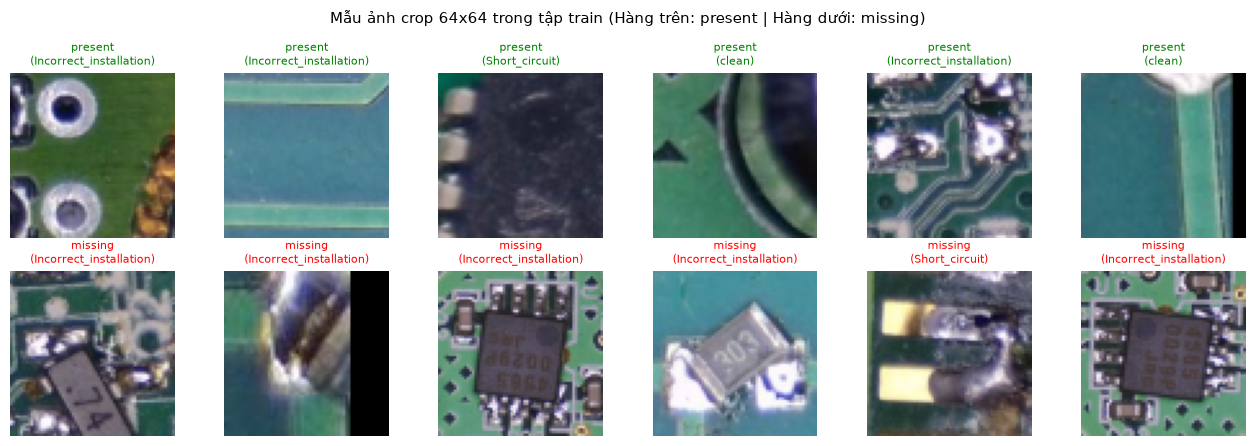

In [3]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
CLASS_NAMES = ["present", "missing"]

def augment_crop(img_rgb: np.ndarray) -> np.ndarray:
    """Augmentation nhẹ: xoay, tỉ lệ, dịch crop mô phỏng sai số alignment, jitter sáng/HSV."""
    h, w = img_rgb.shape[:2]
    angle = random.uniform(-6.0, 6.0)
    scale = random.uniform(0.94, 1.06)
    dx = random.uniform(-3.0, 3.0)
    dy = random.uniform(-3.0, 3.0)
    M = cv2.getRotationMatrix2D((w * 0.5, h * 0.5), angle, scale)
    M[0, 2] += dx
    M[1, 2] += dy
    img = cv2.warpAffine(img_rgb, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)

    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + random.uniform(-6.0, 6.0)) % 180.0
    hsv[..., 1] = np.clip(hsv[..., 1] * random.uniform(0.85, 1.15), 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] * random.uniform(0.82, 1.18), 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

class PCBSlotDataset(Dataset):
    def __init__(self, split_dir: Path, is_train: bool = False):
        self.is_train = is_train
        self.samples = []
        for label, cls_name in [(0, "present"), (1, "missing")]:
            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                continue
            for p in sorted(cls_dir.glob("*.png")):
                slot_id = p.stem.split("__")[-1] if "__" in p.stem else "default"
                self.samples.append((p, label, slot_id))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label, slot_id = self.samples[idx]
        img = cv2.imread(str(path), cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if img.shape[0] != INPUT_SIZE or img.shape[1] != INPUT_SIZE:
            img = cv2.resize(img, (INPUT_SIZE, INPUT_SIZE), interpolation=cv2.INTER_LINEAR)
        if self.is_train:
            img = augment_crop(img)
        x = (img.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
        x = np.transpose(x, (2, 0, 1))
        return torch.from_numpy(x), torch.tensor(label, dtype=torch.long), slot_id

train_ds = PCBSlotDataset(DATA_ROOT / "train", is_train=True)
val_ds   = PCBSlotDataset(DATA_ROOT / "val", is_train=False)
held_ds  = PCBSlotDataset(DATA_ROOT / "heldout", is_train=False)

# Bảng thống kê số lượng mẫu từng tập
summary_rows = []
for name, ds in [("train", train_ds), ("val", val_ds), ("heldout", held_ds)]:
    ys = [lbl for _, lbl, _ in ds.samples]
    n_p, n_m = ys.count(0), ys.count(1)
    summary_rows.append({
        "split": name,
        "present": n_p,
        "missing": n_m,
        "total": len(ys),
        "missing_%": round(100.0 * n_m / max(1, len(ys)), 1),
    })
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

# Hiển thị lưới ảnh mẫu (6 present + 6 missing)
rng_vis = random.Random(SEED)
p_samples = [s for s in train_ds.samples if s[1] == 0]
m_samples = [s for s in train_ds.samples if s[1] == 1]
show_p = rng_vis.sample(p_samples, min(6, len(p_samples)))
show_m = rng_vis.sample(m_samples, min(6, len(m_samples)))
fig, axes = plt.subplots(2, 6, figsize=(13, 4.5))
for col, (p, _, sid) in enumerate(show_p):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    axes[0, col].imshow(img); axes[0, col].set_title(f"present\n({sid})", fontsize=8, color="green"); axes[0, col].axis("off")
for col, (p, _, sid) in enumerate(show_m):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    axes[1, col].imshow(img); axes[1, col].set_title(f"missing\n({sid})", fontsize=8, color="red"); axes[1, col].axis("off")
plt.suptitle("Mẫu ảnh crop 64x64 trong tập train (Hàng trên: present | Hàng dưới: missing)", fontsize=11)
plt.tight_layout(); plt.show()

## Bước 2 - Đánh giá Model TRƯỚC khi train (Pretrained Baseline trên tập `heldout`)

Chạy model `mobilenetv2_050` nguyên bản (mới nạp trọng số ImageNet, **chưa fine-tune** trên dữ liệu PCB) trên đúng tập `heldout` để lấy điểm gốc làm mốc so sánh với model sau khi train.

In [4]:
EPOCHS = 25
BATCH_SIZE = 64
LR = 3e-4

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
held_loader  = DataLoader(held_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

def eval_probs(net, loader):
    net.eval()
    probs, ys, sids = [], [], []
    with torch.no_grad():
        for x, y, sid in loader:
            logits = net(x.to(DEVICE))
            p_miss = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            probs.extend(p_miss.tolist())
            ys.extend(y.numpy().tolist())
            sids.extend(list(sid))
    return np.array(probs), np.array(ys), sids

def compute_metrics(probs, ys, preds):
    tp = int(((preds == 1) & (ys == 1)).sum())
    fn = int(((preds == 0) & (ys == 1)).sum())
    fp = int(((preds == 1) & (ys == 0)).sum())
    tn = int(((preds == 0) & (ys == 0)).sum())
    acc = (tp + tn) / max(1, len(ys))
    prec = tp / max(1, tp + fp)
    rec = tp / max(1, tp + fn)
    f1 = 2 * prec * rec / max(1e-9, prec + rec)
    fpr = fp / max(1, fp + tn)
    auc = float(roc_auc_score(ys, probs)) if len(np.unique(ys)) == 2 else 0.0
    return {
        "Accuracy": acc,
        "Precision": prec,
        "Recall (Missing)": rec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "False Alarm Rate": fpr,
    }

# Khởi tạo model gốc (chưa train trên PCB) và chấm điểm trên heldout
torch.manual_seed(SEED)
model = timm.create_model(MODEL_ARCH, pretrained=True, num_classes=2).to(DEVICE)

pre_probs, pre_ys, pre_sids = eval_probs(model, held_loader)
pre_preds = (pre_probs >= 0.50).astype(int)
pre_results = compute_metrics(pre_probs, pre_ys, pre_preds)
print("=== KẾT QUẢ TRƯỚC KHI TRAIN (Pretrained Baseline - Heldout) ===")
print(pd.Series(pre_results).round(4))

=== KẾT QUẢ TRƯỚC KHI TRAIN (Pretrained Baseline - Heldout) ===
Accuracy            0.4932
Precision           0.4528
Recall (Missing)    0.2243
F1-Score            0.3000
ROC-AUC             0.4719
False Alarm Rate    0.2544
dtype: float64


## Bước 3 - Huấn luyện MobileNetV2 width 0.5 & Biểu đồ Learning Curves

Class weights [present, missing]: [1.0, 0.9762375950813293]
Epoch 01/25 | loss=0.7571 | val_recall=62.5% | val_F1=61.0% | val_FPR=38.35%
Epoch 05/25 | loss=0.5389 | val_recall=72.5% | val_F1=69.6% | val_FPR=32.33%
Epoch 10/25 | loss=0.4223 | val_recall=81.7% | val_F1=76.6% | val_FPR=28.57%
Epoch 15/25 | loss=0.3996 | val_recall=87.5% | val_F1=80.8% | val_FPR=26.32%
Epoch 20/25 | loss=0.3500 | val_recall=87.5% | val_F1=81.1% | val_FPR=25.56%
Epoch 25/25 | loss=0.3481 | val_recall=87.5% | val_F1=80.8% | val_FPR=26.32%


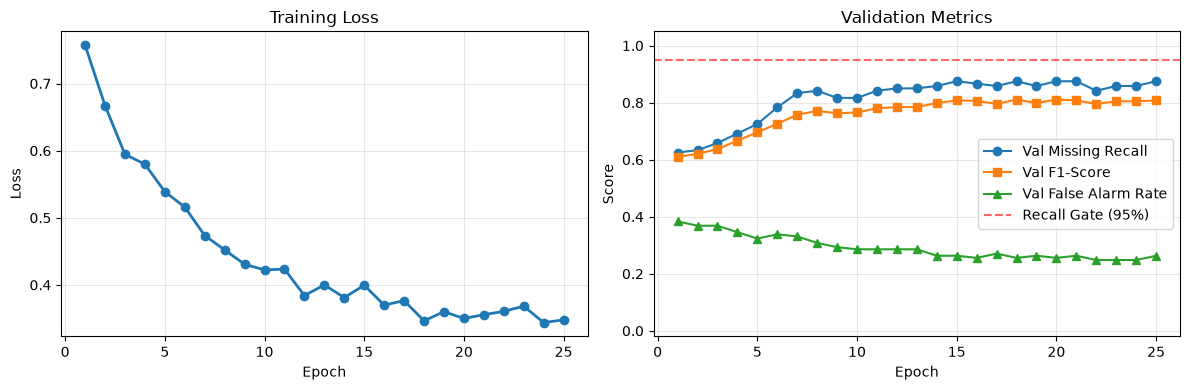

In [5]:
labels_train = [lbl for _, lbl, _ in train_ds.samples]
n_present = max(1, labels_train.count(0))
n_missing = max(1, labels_train.count(1))
class_weights = torch.tensor([1.0, min(5.0, n_present / n_missing)], dtype=torch.float32, device=DEVICE)
print("Class weights [present, missing]:", class_weights.tolist())

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {"epoch": [], "train_loss": [], "val_recall": [], "val_fpr": [], "val_f1": []}
best_score, best_state = -1e9, None

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for x, y, _ in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(x.to(DEVICE)), y.to(DEVICE))
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
    scheduler.step()

    avg_loss = total_loss / max(1, len(train_ds))
    vp, vy, _ = eval_probs(model, val_loader)
    vm = compute_metrics(vp, vy, (vp >= 0.50).astype(int))
    recall, fpr, f1 = vm["Recall (Missing)"], vm["False Alarm Rate"], vm["F1-Score"]

    history["epoch"].append(epoch)
    history["train_loss"].append(avg_loss)
    history["val_recall"].append(recall)
    history["val_fpr"].append(fpr)
    history["val_f1"].append(f1)

    score = recall - 0.5 * fpr
    if score >= best_score:
        best_score = score
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if epoch % 5 == 0 or epoch == EPOCHS or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS} | loss={avg_loss:.4f} | val_recall={recall*100:.1f}% | val_F1={f1*100:.1f}% | val_FPR={fpr*100:.2f}%")

if best_state is not None:
    model.load_state_dict(best_state)
    torch.save(best_state, OUT_DIR / "best.pt")

# Vẽ biểu đồ quá trình huấn luyện
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["epoch"], history["train_loss"], marker="o", linewidth=2)
ax1.set_title("Training Loss"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.grid(alpha=0.3)

ax2.plot(history["epoch"], history["val_recall"], marker="o", label="Val Missing Recall")
ax2.plot(history["epoch"], history["val_f1"], marker="s", label="Val F1-Score")
ax2.plot(history["epoch"], history["val_fpr"], marker="^", label="Val False Alarm Rate")
ax2.axhline(0.95, color="red", linestyle="--", alpha=0.6, label="Recall Gate (95%)")
ax2.set_title("Validation Metrics"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Score"); ax2.set_ylim(-0.02, 1.05)
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Bước 4 - Hiệu chỉnh ngưỡng & So sánh chi tiết TRƯỚC vs SAU khi train (trên tập `heldout`)

Bao gồm:
1. Bảng so sánh tổng hợp (`Pretrained` vs `Fine-tuned` vs `Change`) và biểu đồ cột.
2. Confusion Matrix trước và sau khi train.
3. Bảng điểm chi tiết theo từng slot / loại lỗi.

=== SO SÁNH TRƯỚC vs SAU KHI TRAIN (Heldout Set) ===


,Before (Pretrained),After (Fine-tuned),Change
Accuracy,0.4932,0.7014,0.2081
Precision,0.4528,0.6340,0.1812
Recall (Missing),0.2243,0.9065,0.6822
F1-Score,0.3000,0.7462,0.4462
ROC-AUC,0.4719,0.7701,0.2982
False Alarm Rate,0.2544,0.4912,0.2368


[CẢNH BÁO] Chưa đạt cổng 95% recall (90.65%) -> cân nhắc siết crop margin hoặc đổi MODEL_ARCH = 'mobilenetv2_100'


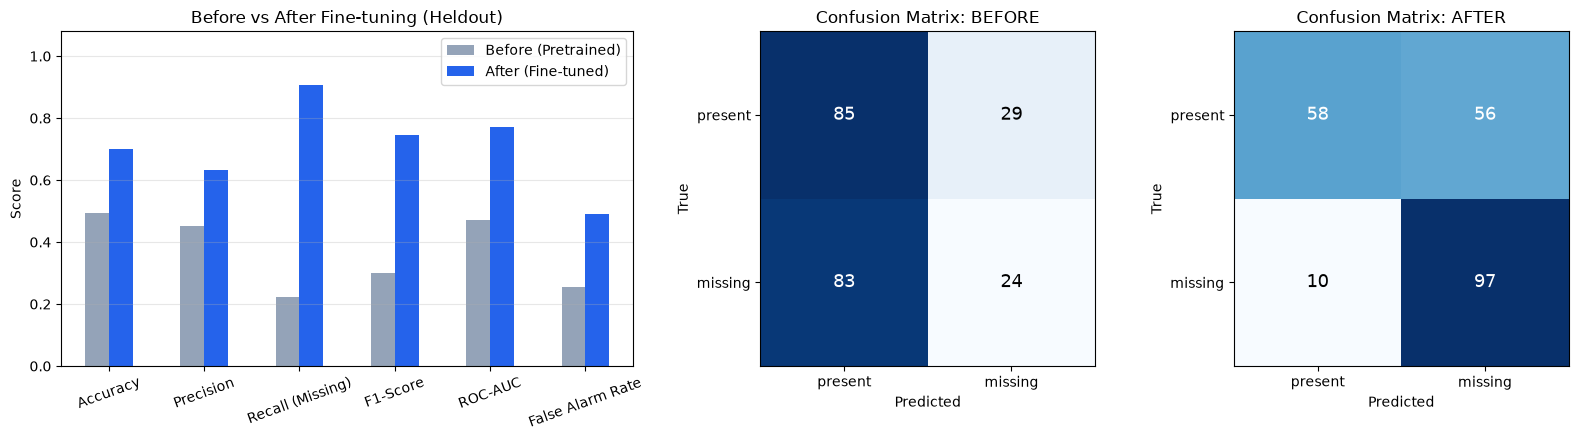

=== CHI TIẾT THEO TỪNG SLOT / LOẠI LỖI (Heldout) ===


,slot / defect,n_samples,threshold,Precision,Recall (Missing),F1-Score,False Alarm Rate
0,Dry_joint,16,0.50,0.7500,0.7500,0.7500,0.2500
1,Incorrect_installation,144,0.34,0.6261,0.9351,0.7500,0.6418
2,Short_circuit,43,0.23,0.6333,0.8636,0.7308,0.5238
3,clean,18,0.85,0.0000,0.0000,0.0000,0.0000


In [6]:
# 1) Hiệu chỉnh ngưỡng trên tập val (giữ recall >= 95% với ngưỡng cao nhất có thể để giảm báo lỗi giả)
vp, vy, vsids = eval_probs(model, val_loader)
per_slot_thresholds = {}
for sid in sorted(set(vsids)):
    idx = [i for i, s in enumerate(vsids) if s == sid]
    sp, sy = vp[idx], vy[idx]
    best_th = 0.50
    for th in np.linspace(0.20, 0.85, 66):
        pred = (sp >= th).astype(int)
        miss_mask = (sy == 1)
        rec = float((pred[miss_mask] == 1).mean()) if miss_mask.any() else 1.0
        if rec >= 0.95:
            best_th = round(float(th), 3)
    per_slot_thresholds[sid] = best_th

# 2) Chấm điểm model SAU khi train trên cùng tập heldout
ft_probs, ft_ys, ft_sids = eval_probs(model, held_loader)
ft_preds = np.array([1 if p >= per_slot_thresholds.get(s, 0.50) else 0 for p, s in zip(ft_probs, ft_sids)])
ft_results = compute_metrics(ft_probs, ft_ys, ft_preds)

held_recall = ft_results["Recall (Missing)"]
held_prec = ft_results["Precision"]
held_fpr = ft_results["False Alarm Rate"]

# 3) Bảng so sánh TRƯỚC vs SAU
comparison = pd.DataFrame({"Before (Pretrained)": pre_results, "After (Fine-tuned)": ft_results})
comparison["Change"] = comparison["After (Fine-tuned)"] - comparison["Before (Pretrained)"]
print("=== SO SÁNH TRƯỚC vs SAU KHI TRAIN (Heldout Set) ===")
display(comparison.round(4))
comparison.round(4).to_csv(OUT_DIR / "before_after_comparison.csv")

if held_recall >= 0.95:
    print(f"[PASS] Đạt cổng chất lượng: Missing Recall = {held_recall*100:.2f}% >= 95% | False Alarm Rate = {held_fpr*100:.2f}%")
else:
    print(f"[CẢNH BÁO] Chưa đạt cổng 95% recall ({held_recall*100:.2f}%) -> cân nhắc siết crop margin hoặc đổi MODEL_ARCH = 'mobilenetv2_100'")

# 4) Biểu đồ cột so sánh + Confusion Matrix Trước vs Sau
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.6, 1, 1]})

comparison[["Before (Pretrained)", "After (Fine-tuned)"]].plot(kind="bar", ax=axes[0], rot=20, color=["#94a3b8", "#2563eb"])
axes[0].set_title("Before vs After Fine-tuning (Heldout)")
axes[0].set_ylabel("Score"); axes[0].set_ylim(0, 1.08); axes[0].grid(axis="y", alpha=0.3)

for ax, title, y_true, y_pred in [
    (axes[1], "Confusion Matrix: BEFORE", pre_ys, pre_preds),
    (axes[2], "Confusion Matrix: AFTER",  ft_ys,  ft_preds),
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks([0, 1]); ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticks([0, 1]); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=13,
                    color="white" if cm[r, c] > cm.max() * 0.5 else "black")
plt.tight_layout(); plt.show()

# 5) Bảng điểm chi tiết theo từng slot / loại lỗi
slot_rows = []
for sid in sorted(set(ft_sids)):
    idx = [i for i, s in enumerate(ft_sids) if s == sid]
    m = compute_metrics(ft_probs[idx], ft_ys[idx], ft_preds[idx])
    slot_rows.append({
        "slot / defect": sid,
        "n_samples": len(idx),
        "threshold": per_slot_thresholds.get(sid, 0.50),
        "Precision": m["Precision"],
        "Recall (Missing)": m["Recall (Missing)"],
        "F1-Score": m["F1-Score"],
        "False Alarm Rate": m["False Alarm Rate"],
    })
per_slot_df = pd.DataFrame(slot_rows)
print("=== CHI TIẾT THEO TỪNG SLOT / LOẠI LỖI (Heldout) ===")
display(per_slot_df.round(4))

## Bước 5 - So sánh trực quan từng ảnh (Qualitative Results: Trước vs Sau)

Chọn ngẫu nhiên 4 ảnh `present` và 4 ảnh `missing` từ tập `heldout` để nhìn trực tiếp dự đoán và xác suất `p(missing)` của model **trước** và **sau** khi train.

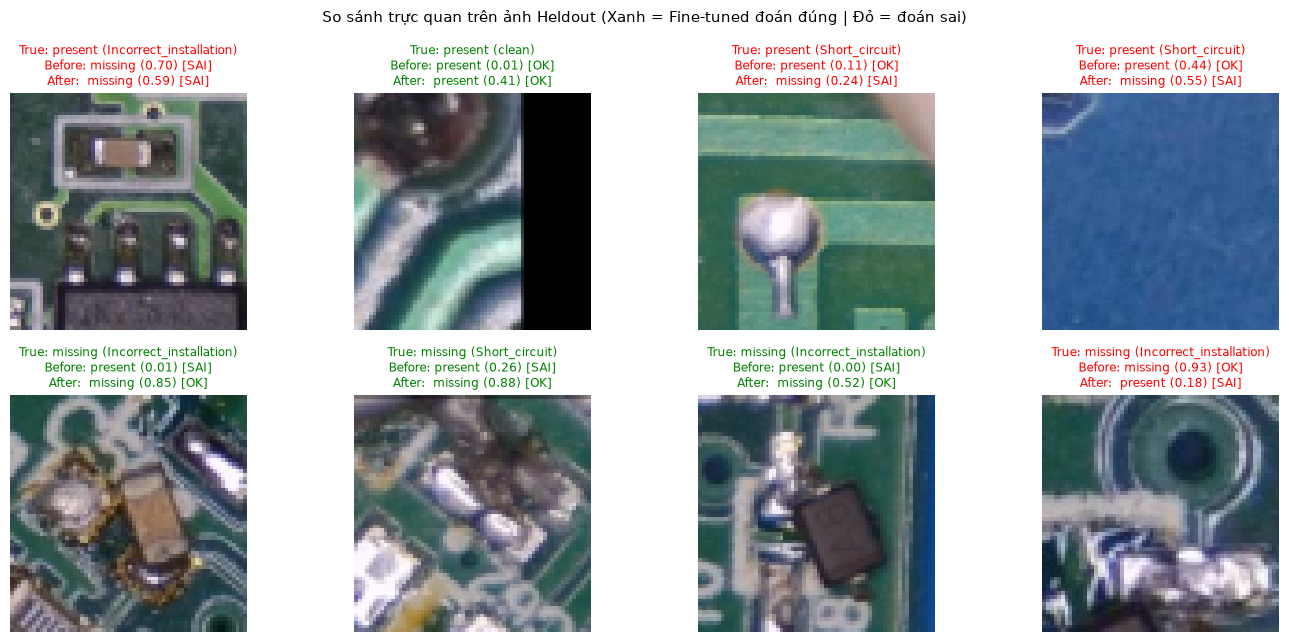

In [7]:
rng_q = random.Random(SEED)
idx_present = [i for i, (_, y, _) in enumerate(held_ds.samples) if y == 0]
idx_missing = [i for i, (_, y, _) in enumerate(held_ds.samples) if y == 1]
picked_idx = rng_q.sample(idx_present, min(4, len(idx_present))) + rng_q.sample(idx_missing, min(4, len(idx_missing)))

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, idx in zip(axes.ravel(), picked_idx):
    path, y_true, sid = held_ds.samples[idx]
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    p_pre, pred_pre = pre_probs[idx], pre_preds[idx]
    p_ft,  pred_ft  = ft_probs[idx],  ft_preds[idx]

    ok_pre = "OK" if pred_pre == y_true else "SAI"
    ok_ft  = "OK" if pred_ft  == y_true else "SAI"
    title_color = "green" if pred_ft == y_true else "red"

    ax.imshow(img)
    ax.set_title(
        f"True: {CLASS_NAMES[y_true]} ({sid})\n"
        f"Before: {CLASS_NAMES[pred_pre]} ({p_pre:.2f}) [{ok_pre}]\n"
        f"After:  {CLASS_NAMES[pred_ft]} ({p_ft:.2f}) [{ok_ft}]",
        fontsize=8.5,
        color=title_color,
    )
    ax.axis("off")
plt.suptitle("So sánh trực quan trên ảnh Heldout (Xanh = Fine-tuned đoán đúng | Đỏ = đoán sai)", fontsize=11)
plt.tight_layout(); plt.show()

## Bước 6 - Xuất ONNX (opset 17, dynamic batch), kiểm tra toán tử & lưu tập hiệu chuẩn INT8

In [8]:
ALLOWED_OPS = {"Conv", "Clip", "Relu", "Add", "GlobalAveragePool", "AveragePool", "MaxPool", "Flatten", "Reshape", "Gemm", "Constant"}

onnx_path = OUT_DIR / f"{MODEL_ARCH}_{DATASET_VERSION}.onnx"
model.eval().cpu()
dummy = torch.randn(1, 3, INPUT_SIZE, INPUT_SIZE)
torch.onnx.export(
    model,
    dummy,
    str(onnx_path),
    opset_version=17,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
    do_constant_folding=True,
    dynamo=False,
)

# Kiểm tra danh sách toán tử ONNX
om = onnx.load(str(onnx_path))
onnx.checker.check_model(om)
used_ops = {node.op_type for node in om.graph.node}
disallowed = used_ops - ALLOWED_OPS
print("ONNX ops used:", sorted(used_ops))
assert not disallowed, f"Phát hiện toán tử không nằm trong danh sách portable: {disallowed}"
print("[PASS] Toàn bộ toán tử ONNX đạt chuẩn portability!")

# Đo kiểm lại độ lệch đầu ra giữa PyTorch và ONNX Runtime
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
test_batch = torch.randn(40, 3, INPUT_SIZE, INPUT_SIZE)
with torch.no_grad():
    pt_out = model(test_batch).numpy()
ort_out = sess.run(None, {"input": test_batch.numpy()})[0]
max_diff = float(np.max(np.abs(pt_out - ort_out)))
print(f"Max diff PyTorch vs ONNX Runtime (batch 40): {max_diff:.6f}")

# Đo lại accuracy trực tiếp bằng ONNX Runtime trên tập heldout (theo spec: re-check accuracy after export)
ort_probs, ort_ys, ort_sids = [], [], []
for x, y, sid in held_loader:
    logits = sess.run(None, {"input": x.numpy()})[0]
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    p_miss = e[:, 1] / e.sum(axis=1)
    ort_probs.extend(p_miss.tolist())
    ort_ys.extend(y.numpy().tolist())
    ort_sids.extend(list(sid))
ort_pred = np.array([1 if p >= per_slot_thresholds.get(s, 0.50) else 0 for p, s in zip(ort_probs, ort_sids)])
ort_metrics = compute_metrics(np.array(ort_probs), np.array(ort_ys), ort_pred)
print("=== XÁC NHẬN SAU XUẤT ONNX (ONNX Runtime CPU - Heldout) ===")
print(pd.Series(ort_metrics).round(4))

# Lưu tập hiệu chuẩn INT8 (tối đa 200 ảnh crop thật từ tập val)
calib_dir = OUT_DIR / "int8_calibration_crops"
calib_dir.mkdir(exist_ok=True)
for p, _, _ in val_ds.samples[:200]:
    (calib_dir / p.name).write_bytes(p.read_bytes())

# Lưu metadata phiên bản model + ngưỡng từng slot
meta = {
    "model_arch": MODEL_ARCH,
    "dataset_version": DATASET_VERSION,
    "input_size": INPUT_SIZE,
    "opset": 17,
    "used_ops": sorted(used_ops),
    "before_metrics": {k: round(v, 4) for k, v in pre_results.items()},
    "after_metrics": {k: round(v, 4) for k, v in ft_results.items()},
    "onnx_metrics": {k: round(v, 4) for k, v in ort_metrics.items()},
    "per_slot_thresholds": per_slot_thresholds,
}
(OUT_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("Đã lưu model + metadata + CSV so sánh + INT8 calibration set tại:", OUT_DIR)

C:\Users\Minor\AppData\Local\Temp\ipykernel_13128\3902664939.py:6: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX ops used: ['Add', 'Clip', 'Constant', 'Conv', 'Flatten', 'Gemm', 'GlobalAveragePool']
[PASS] Toàn bộ toán tử ONNX đạt chuẩn portability!
Max diff PyTorch vs ONNX Runtime (batch 40): 0.000000
=== XÁC NHẬN SAU XUẤT ONNX (ONNX Runtime CPU - Heldout) ===
Accuracy            0.7014
Precision           0.6340
Recall (Missing)    0.9065
F1-Score            0.7462
ROC-AUC             0.7701
False Alarm Rate    0.4912
dtype: float64
Đã lưu model + metadata + CSV so sánh + INT8 calibration set tại: exports\mobilenetv2_050_pcb_defects_obb_v1.0
